# Experiment Design and Targeting Models

**Part A:** Did moving a game's progression gate from level 30 to level 40 change player retention? (A/B test, Cookie Cats)
**Part B:** Whom should a bank's telemarketing team call first? (classification comparison, UCI Bank Marketing)

Both datasets are public. The business problems are realistic framings, not client engagements.

**To run:** put `cookie_cats.csv` and `bank-additional-full.csv` next to this notebook, together with `ab_test_analysis.py` and `targeting_models.py`, then run all cells top to bottom. Seed 42 is used throughout.

In [5]:
from google.colab import files
uploaded = files.upload()

Saving cookie_cats.csv to cookie_cats.csv


In [6]:
from google.colab import files
uploaded = files.upload()

Saving bank-additional-full.csv to bank-additional-full.csv


In [4]:
from google.colab import files
uploaded = files.upload()

Saving ab_test_analysis.py to ab_test_analysis.py
Saving targeting_models.py to targeting_models.py


## 0. Setup

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ab_test_analysis as ab
import targeting_models as tm

pd.set_option("display.float_format", "{:.4f}".format)
SEED = 42

# Files
DATA_DIR = Path(".")
COOKIE_CATS = DATA_DIR / "cookie_cats.csv"
BANK = DATA_DIR / "bank-additional-full.csv"

# Speed settings (the reported results used the values shown here)
N_BOOT, N_PERM = 5000, 10000     # bootstrap resamples, permutations
PEEK_SIMS = 2000                 # A/A simulations for the peeking check
CV_FOLDS = 5
TUNE_K, DEFAULT_K = True, 200    # set TUNE_K = False to skip the slow KNN search
K_GRID = (5, 15, 25, 50, 100, 200)
RUN_OPTIONAL = False             # extra robustness checks at the end (not used in the report)

for f in (COOKIE_CATS, BANK):
    assert f.exists(), f"Missing {f}. Put the CSV next to the notebook or change DATA_DIR."

# Part A: Did the gate change improve retention?

## A1. Business problem, hypotheses and design
A studio moved the first progression gate from level 30 to level 40. A change that hurts retention can cost revenue; delaying a good change wastes opportunity.

| ID | Null hypothesis | Test |
|---|---|---|
| H0-SRM | Users were allocated 50/50 | Chi-square goodness of fit |
| H1 | 1-day retention equal in both arms | Two-proportion z-test, bootstrap CI |
| H2 | 7-day retention equal in both arms (**primary**) | Two-proportion z-test, bootstrap CI |
| H3 | Game-rounds distribution the same in both arms | Permutation test (mean, median), Mann-Whitney |
| H4 | Repeated looks do not inflate false positives | A/A peeking simulation |

**Design choices made before looking at outcomes:** primary metric is 7-day retention; assumed baseline 19%; minimum detectable effect (MDE) 1 percentage point; alpha 0.05; power 0.80. The baseline and MDE are assumptions, not values from a prior period.

In [8]:
P_BASE, MDE_ABS, ALPHA, POWER = 0.19, 0.01, 0.05, 0.80
n_c, n_t = ab.sample_size_two_proportions(P_BASE, MDE_ABS, ALPHA, POWER)
print(f"Required sample size per group for a {MDE_ABS*100:.1f} pp MDE: {n_c:,}")

tradeoff = pd.DataFrame({"mde_pp": [0.005, 0.0075, 0.01, 0.015, 0.02]})
tradeoff["n_per_group"] = [ab.sample_size_two_proportions(P_BASE, d, ALPHA, POWER)[0] for d in tradeoff.mde_pp]
tradeoff

Required sample size per group for a 1.0 pp MDE: 24,638


,mde_pp,n_per_group
0,0.0050,97601
1,0.0075,43591
2,0.0100,24638
3,0.0150,11054
4,0.0200,6276


## A2. Data checks

In [9]:
df = pd.read_csv(COOKIE_CATS)   # userid, version, sum_gamerounds, retention_1, retention_7
checks = ab.basic_data_checks(df, value_cols=["sum_gamerounds"])
print("rows:", checks["rows"], "| duplicate ids:", checks["duplicate_ids"])
print("missing values:", sum(checks["missing_by_col"].values()))
print("group sizes:", checks["group_counts"])

c_n = int((df.version == "gate_30").sum()); t_n = int((df.version == "gate_40").sum())
srm = ab.sample_ratio_check(c_n, t_n)
print(f"Sample-ratio check: chi2 = {srm['chi2']:.2f}, p = {srm['p_value']:.4f}, control share = {srm['observed_share_control']:.4f}")

rows: 90189 | duplicate ids: 0
missing values: 0
group sizes: {'gate_40': 45489, 'gate_30': 44700}
Sample-ratio check: chi2 = 6.90, p = 0.0086, control share = 0.4956


        userid  version  sum_gamerounds
57702  6390605  gate_30           49854
7912    871500  gate_30            2961
29417  3271615  gate_40            2640
43671  4832608  gate_30            2438
48188  5346171  gate_40            2294
share with zero rounds: 0.0443


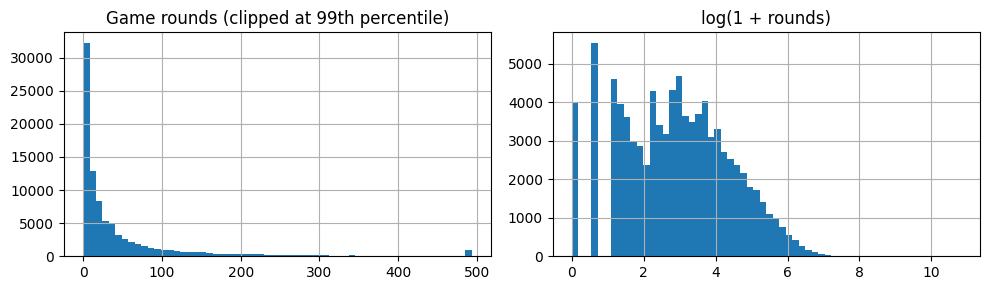

In [10]:
print(df.nlargest(5, "sum_gamerounds")[["userid", "version", "sum_gamerounds"]])
print("share with zero rounds:", round((df.sum_gamerounds == 0).mean(), 4))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
df.sum_gamerounds.clip(upper=df.sum_gamerounds.quantile(.99)).hist(bins=60, ax=ax[0])
ax[0].set_title("Game rounds (clipped at 99th percentile)")
np.log1p(df.sum_gamerounds).hist(bins=60, ax=ax[1])
ax[1].set_title("log(1 + rounds)")
plt.tight_layout(); plt.show()

**Observations from the executed run:** no duplicates or missing values. The sample-ratio check gave p = 0.0086 (control 49.56% of users). That is below 0.01 but above the stricter 0.001 alert level many teams use, so it is treated as a flag to investigate, not as proof of broken randomisation. One gate_30 player has 49,854 rounds (the next highest is 2,961), so the rounds metric is very skewed.

## A3. Retention: two-proportion z-test and bootstrap CI
Assumes independent users and a large sample. If users were clustered, a cluster bootstrap would replace both.

In [11]:
res = ab.analyse_cookie_cats(df, control="gate_30", treatment="gate_40",
                             seed=SEED, n_boot=N_BOOT, n_perm=N_PERM)

rows = []
for m in ["retention_1", "retention_7"]:
    z, b = res[m]["ztest"], res[m]["bootstrap"]
    rows.append({"metric": m, "gate_30": z["p_control"], "gate_40": z["p_treatment"],
                 "diff_pp": 100*z["diff"], "z_ci_low_pp": 100*z["ci_low"], "z_ci_high_pp": 100*z["ci_high"],
                 "boot_ci_low_pp": 100*b["ci_low"], "boot_ci_high_pp": 100*b["ci_high"],
                 "relative_change": z["rel_lift"], "p_value": z["p_value"]})
retention = pd.DataFrame(rows)
retention

,metric,gate_30,gate_40,diff_pp,z_ci_low_pp,z_ci_high_pp,boot_ci_low_pp,boot_ci_high_pp,relative_change,p_value
0,retention_1,0.4482,0.4423,-0.5905,-1.2392,0.0582,-1.2217,0.0566,-0.0132,0.0744
1,retention_7,0.1902,0.1820,-0.8201,-1.3282,-0.3121,-1.3278,-0.3226,-0.0431,0.0016


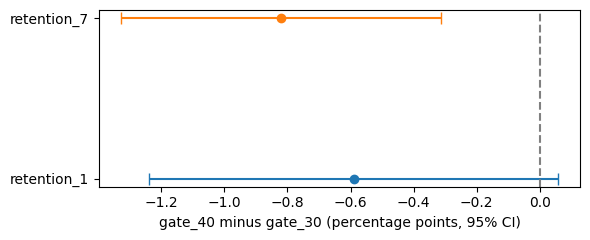

In [12]:
fig, ax = plt.subplots(figsize=(6, 2.5))
for i, r in retention.iterrows():
    ax.errorbar(r.diff_pp, i, xerr=[[r.diff_pp - r.z_ci_low_pp], [r.z_ci_high_pp - r.diff_pp]], fmt="o", capsize=4)
ax.axvline(0, color="grey", linestyle="--")
ax.set_yticks(range(len(retention))); ax.set_yticklabels(retention.metric)
ax.set_xlabel("gate_40 minus gate_30 (percentage points, 95% CI)")
plt.tight_layout(); plt.show()

## A4. Game rounds: permutation test
Rounds are heavy-tailed, so the permutation test (valid under randomisation) is used for the mean and the median; Mann-Whitney is a rank-based cross-check.

In [13]:
for k, v in res["gamerounds_permutation"].items():
    print(f"{k}: difference = {v['observed_diff']:.3f}, permutation p = {v['p_value']:.4f}")
print(f"Mann-Whitney p = {res['gamerounds_mannwhitney_p']:.4f}")

mean: difference = -1.157, permutation p = 0.4616
median: difference = -1.000, permutation p = 0.8924
Mann-Whitney p = 0.0502


## A5. Multiple metrics and the peeking simulation

In [14]:
res["multiple_testing"]

,metric,raw_p,holm_p,bonferroni_p
0,retention_1,0.0744,0.1488,0.2232
1,retention_7,0.0016,0.0047,0.0047
2,gamerounds_mean,0.4616,0.4616,1.0000


,false_positive_rate
One look at planned sample size,0.0515
Stop at first p < 0.05 (10 looks),0.1920
Bonferroni-corrected looks,0.0240


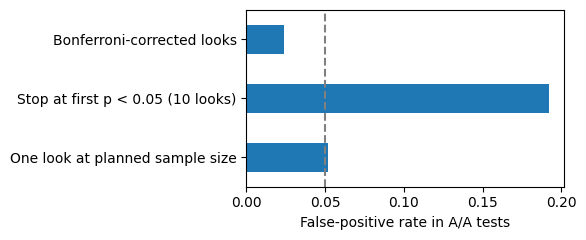

In [15]:
peek = ab.simulate_peeking(p=P_BASE, n_total=2*n_c, n_looks=10, n_sims=PEEK_SIMS, seed=SEED)
peek_tbl = pd.Series({"One look at planned sample size": peek["fixed_single_look_fpr"],
                      "Stop at first p < 0.05 (10 looks)": peek["peeking_fpr"],
                      "Bonferroni-corrected looks": peek["bonferroni_looks_fpr"]}, name="false_positive_rate")
display(peek_tbl)
peek_tbl.plot.barh(figsize=(6, 2.5)); plt.axvline(0.05, color="grey", linestyle="--")
plt.xlabel("False-positive rate in A/A tests"); plt.tight_layout(); plt.show()

In [16]:
n_obs = min(c_n, t_n)
print("Power to detect the planned MDE at the observed sample size:",
      round(ab.power_two_proportions(P_BASE, MDE_ABS, n_obs, ALPHA), 3))
print("Smallest effect detectable with 80% power at the observed size (pp):",
      round(100 * ab.minimum_detectable_effect(P_BASE, n_obs, ALPHA, POWER), 2))

Power to detect the planned MDE at the observed sample size: 0.965
Smallest effect detectable with 80% power at the observed size (pp): 0.74


## A6. Results and recommendation

**From the executed run**

| Metric | gate_30 | gate_40 | Difference (95% CI) | Holm-adjusted p |
|---|---|---|---|---|
| 1-day retention | 44.82% | 44.23% | -0.59 pp (-1.24 to +0.06) | 0.149 |
| 7-day retention | 19.02% | 18.20% | -0.82 pp (-1.33 to -0.31) | 0.0047 |
| Game rounds, mean | | | -1.16 (permutation p = 0.46) | 0.46 |

- The 7-day drop (about -4.3% relative) survives multiple-testing correction and the whole interval is below zero.
- Peeking: stopping at the first p < 0.05 across 10 looks gave a 19.2% false-positive rate versus 5.2% for one planned look and 2.4% for a corrected rule.
- Mann-Whitney on rounds gave p = 0.050, borderline.

**Recommendation: do not ship the level-40 gate as tested.**

**Limitations:** unresolved sample-ratio flag; the effect of the 49,854-round player on the rounds result was not tested; only retention and rounds were measured (no revenue); baseline and MDE were assumptions; no novelty or day-of-week checks.

# Part B: Whom should we contact?

## B1. Business problem, hypotheses and data
A bank's telemarketing team can only call part of its list, so it needs customers ranked by likelihood of subscribing to a term deposit.

| ID | Null hypothesis | Test |
|---|---|---|
| H5 | Gradient boosting and logistic regression have equal PR-AUC / recall at the top 10% | Paired bootstrap CI |
| H6 | Gradient boosting and KNN have equal PR-AUC / recall at the top 10% | Paired bootstrap CI |
| H7 | The post-call `duration` field does not inflate performance | With versus without comparison |
| H8 | Random-CV performance carries over to later data | Time-ordered split |
| H9 | Macro-economic indicators do not drive performance | Rerun without them |

**`duration` is dropped.** Call length is only known after the call, so a model using it cannot rank customers before dialling (target leakage).

In [17]:
bank = tm.load_bank(BANK)
print(bank.shape, f"| subscribe rate = {bank.y.mean():.4f}")

X = bank.drop(columns=["y"] + tm.LEAKY)                                  # drop `duration`
X = X.assign(prev_contacted=(~X.pdays.isin([-1, 999])).astype(int))      # pdays 999/-1 = never contacted
y = bank["y"]
num, cat = tm.split_columns(X)
print(len(num), "numeric and", len(cat), "categorical features")

(41188, 21) | subscribe rate = 0.1127
10 numeric and 10 categorical features


## B2. Cross-validated comparison on identical stratified folds
Preprocessing (scaling, one-hot encoding) sits inside the pipelines, so it is fitted on training folds only. KNN's k is tuned by average precision.

In [18]:
if TUNE_K:
    best_k, knn_grid = tm.tune_knn_k(X, y, num, cat, k_grid=K_GRID, cv=CV_FOLDS)
else:
    best_k = DEFAULT_K
print("k used for KNN:", best_k, "(edge of the grid)" if best_k == max(K_GRID) else "")

models = tm.build_models(num, cat, k=best_k)
folds = tm.per_fold_metrics(models, X, y, n_splits=CV_FOLDS)
folds.drop(columns="fold").groupby("model").agg(["mean", "std"])

k used for KNN: 200 (edge of the grid)


pr_auc        roc_auc        recall@10%        lift@10%       
         mean    std    mean    std       mean    std     mean    std
model                                                                
gboost 0.4725 0.0254  0.8048 0.0065     0.4550 0.0115   4.5496 0.1147
knn    0.3852 0.0143  0.7740 0.0056     0.4140 0.0094   4.1401 0.0938
logreg 0.4520 0.0211  0.7916 0.0076     0.4364 0.0171   4.3642 0.1711

In [19]:
oof = tm.oof_scores(models, X, y, n_splits=CV_FOLDS)
cv_table = pd.DataFrame({name: tm.metric_row(y, s) for name, s in oof.items()}).T
cv_table

,pr_auc,roc_auc,recall@10%,lift@10%
logreg,0.4514,0.7915,0.4364,4.3642
knn,0.3834,0.7737,0.4129,4.1293
gboost,0.4691,0.8042,0.4573,4.5733


## B3. Are the differences real? Paired bootstrap on the metric difference
The same rows are resampled for both models. The interval reflects test-row noise only, not retraining variability.

In [20]:
rows = []
for a, b in [("gboost", "logreg"), ("gboost", "knn"), ("logreg", "knn")]:
    for m in ["pr_auc", "recall@10%"]:
        rows.append({"A": a, "B": b, "metric": m, **tm.paired_bootstrap_diff(y, oof[a], oof[b], metric=m)})
pd.DataFrame(rows)

,A,B,metric,diff,ci_low,ci_high
0,gboost,logreg,pr_auc,0.0176,0.0111,0.0245
1,gboost,logreg,recall@10%,0.0209,0.0126,0.0289
2,gboost,knn,pr_auc,0.0857,0.0756,0.0947
3,gboost,knn,recall@10%,0.0444,0.0350,0.0527
4,logreg,knn,pr_auc,0.0680,0.0581,0.0773
5,logreg,knn,recall@10%,0.0235,0.0148,0.0316


## B4. Leakage check: with versus without `duration`

In [21]:
def factory(Xs):
    n_, c_ = tm.split_columns(Xs)
    return tm.build_models(n_, c_)

tm.leakage_check(factory, bank.drop(columns=["y"]), y, n_splits=CV_FOLDS)

,pr_auc,roc_auc,recall@10%,lift@10%
without_leaky,0.4691,0.8042,0.4573,4.5733
with_leaky,0.6678,0.9496,0.5819,5.8190


## B5. Calling-list gains
If the team calls customers in score order, what share of subscribers does each portion of the list reach?

,decile,size,sum,cum_capture,cum_call_share
0,1,4119,2122,0.4573,0.1000
1,2,4119,883,0.6476,0.2000
2,3,4119,343,0.7216,0.3000
3,4,4119,267,0.7791,0.4000
4,5,4118,225,0.8276,0.5000
5,6,4119,211,0.8731,0.6000
6,7,4119,165,0.9086,0.7000
7,8,4119,165,0.9442,0.8000
8,9,4119,151,0.9767,0.9000
9,10,4118,108,1.0000,1.0000


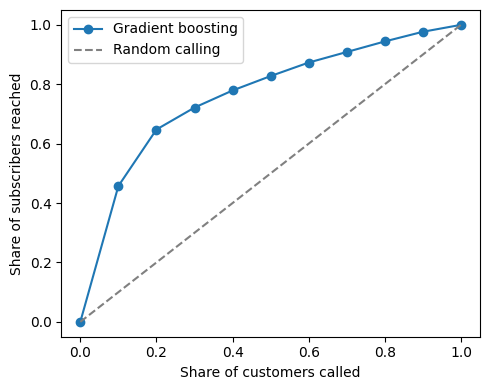

In [22]:
gains = tm.gains_table(y, oof["gboost"])
display(gains)
plt.figure(figsize=(5, 4))
plt.plot([0] + list(gains.cum_call_share), [0] + list(gains.cum_capture), marker="o", label="Gradient boosting")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Random calling")
plt.xlabel("Share of customers called"); plt.ylabel("Share of subscribers reached")
plt.legend(); plt.tight_layout(); plt.show()

## B6. Does random CV carry over to later data? Time-ordered split
Rows are in date order. Train on the earliest 70%, test on the latest 30%. The later period has a different subscribe rate, so PR-AUC is not comparable with the CV table; use ROC-AUC and top-10% lift.

In [23]:
def factory_k(Xs):
    n_, c_ = tm.split_columns(Xs)
    return tm.build_models(n_, c_, k=best_k)

time_res, test_pos_rate = tm.time_split_eval(factory_k, X, y, train_frac=0.70)
print(f"Subscribe rate in the later 30%: {test_pos_rate:.4f} (overall {y.mean():.4f})")
time_res

Subscribe rate in the later 30%: 0.2455 (overall 0.1127)


,pr_auc,roc_auc,recall@10%,lift@10%
logreg,0.3911,0.6665,0.1875,1.8754
knn,0.2273,0.4912,0.0646,0.6460
gboost,0.3118,0.5691,0.1559,1.5590


## B7. How much do the macro-economic columns matter?
These columns mostly identify when a call happened.

In [24]:
macro_cols = [c for c in tm.MACRO_COLS if c in X.columns]
macro_cmp = tm.drop_columns_comparison(factory_k, X, y, macro_cols, n_splits=CV_FOLDS)
macro_cmp.pivot(index="model", columns="setting", values=["pr_auc", "recall@10%"])

pr_auc                recall@10%             
setting all_features without_cols all_features without_cols
model                                                      
gboost        0.4691       0.4216       0.4573       0.4297
knn           0.3834       0.3342       0.4129       0.3869
logreg        0.4514       0.4015       0.4364       0.4138

## B8. Results and recommendation

**From the executed run (random 5-fold stratified CV)**

| Model | PR-AUC | Recall @ top 10% | Lift @ top 10% |
|---|---|---|---|
| Logistic regression | 0.451 | 0.436 | 4.36 |
| KNN (k = 200) | 0.383 | 0.413 | 4.13 |
| Gradient boosting | 0.469 | 0.457 | 4.57 |

- Paired bootstrap: gradient boosting beats logistic regression by +0.018 PR-AUC (CI 0.011 to 0.025) and beats KNN by +0.086 (CI 0.076 to 0.095).
- Leakage: with `duration`, PR-AUC would be 0.668 instead of 0.469.
- Macro columns add about 0.05 PR-AUC; the model ranking is unchanged without them.
- Gains: the top 10% of scores reaches 45.7% of subscribers, the top 20% reaches 64.8%.
- **Time-ordered split:** the later period has a 24.55% subscribe rate. Top-10% lift falls to 1.88 (logistic regression), 1.56 (gradient boosting) and 0.65 (KNN); KNN's ROC-AUC (0.49) is no better than chance. The ranking reverses relative to random CV, so random CV was optimistic.

**Recommendation:** use logistic regression for deployment. Gradient boosting wins under random CV, but the time-ordered split is closer to real use and favours logistic regression, which is also simpler to explain and monitor. Rank customers by predicted probability and call from the top; where to stop depends on call cost, which the data does not contain.

**Limitations:** the time-split result is one split with no confidence interval; rolling windows and a time split without macro columns were not run, so the reason for the degradation is unexplained; KNN's best k sits at the edge of the grid; paired CIs ignore retraining variability; k was tuned on data later used for CV; one Portuguese bank, 2008 to 2010.

# Method-justification table

| Method | Why used | Key assumption | If it fails |
|---|---|---|---|
| Power and sample size | Fix n and MDE before seeing outcomes | Normal approximation, known baseline | Simulate power |
| Sample-ratio check | Detect broken randomisation | Planned split known | Investigate logging and assignment |
| Two-proportion z-test | Compare binary retention | Independent users, large n | Fisher exact, cluster-robust methods |
| Bootstrap CI | Interval without a formula | i.i.d. users | Cluster bootstrap |
| Permutation test | Skewed rounds metric | Exchangeable under H0 | Rank or log-scale analysis |
| Holm correction | Control false positives across metrics | Fixed set of metrics | Benjamini-Hochberg |
| Peeking simulation | Show inflation from repeated looks | A/A simulation mirrors the stopping rule | Group-sequential designs |
| Stratified k-fold | Keep ~11% positives per fold | Rows independent | Group or time-based folds |
| PR-AUC, top-10% recall and lift | Imbalanced data, limited call budget | Top 10% matches real capacity | Set cutoff from call budget |
| Logistic regression | Interpretable baseline | Roughly linear log-odds | Interactions, splines, trees |
| KNN | Distance-based comparison | Scaled features, sensible k | PCA; weak in high-dimensional one-hot space |
| Gradient boosting | Non-linearity and interactions | Enough data, regularised | Simpler model |
| Paired bootstrap | Test model gaps rather than eyeball them | Same rows scored by both | Repeated CV, nested CV |
| Dropping `duration` | Post-call leakage | n/a | n/a |
| Time-ordered split | Test whether random CV is optimistic | Rows in date order | Rolling-origin validation |

# Optional extensions (not used in the report)
Set `RUN_OPTIONAL = True` in the setup cell to run these. They test claims the report leaves open: whether one extreme player drives the game-rounds result, how stable the out-of-time ranking is across several windows, and whether gradient boosting beats logistic regression fold by fold.

In [25]:
if RUN_OPTIONAL:
    display(ab.outlier_sensitivity(df, n_perm=N_PERM // 2, seed=SEED))

In [26]:
if RUN_OPTIONAL:
    macro_free = X.drop(columns=macro_cols)
    roll = tm.rolling_time_eval(factory_k, X, y, n_windows=4, initial_frac=0.5)
    roll_nm = tm.rolling_time_eval(factory_k, macro_free, y, n_windows=4, initial_frac=0.5)
    cols = ["window", "model", "test_pos_rate", "roc_auc", "lift@10%", "pr_auc_vs_base"]
    print("All features"); display(roll[cols])
    print("Without macro columns"); display(roll_nm[cols])

In [27]:
if RUN_OPTIONAL:
    display(tm.paired_fold_differences(folds, "gboost", "logreg"))